## Entrenamiento y comparación de modelos

El notebook debe entrenar y comparar dos modelos principales:

| Modelo | Características | Obligatorio |
|---|---|---|
| **CNN propia** | Arquitectura construida desde cero | ✅ Sí |
| **MobileNetV2** | Transfer Learning | ✅ Sí |
| **CNN de larvas** | Clasificación microscópica | Opcional |

### Clases de clasificación

Ambos modelos principales identificarán las siguientes especies:

1. **Aedes aegypti**
2. **Aedes albopictus**
3. **Culex**

### Métrica principal

La métrica principal para evaluar y comparar los modelos será:

**F1-score macro ≥ 0,85**

### Métricas adicionales

También se deberán calcular las siguientes métricas:

1. **Accuracy**
2. **Precision por clase**
3. **Recall por clase**
4. **F1-score por clase**
5. **Matriz de confusión**
6. **Curvas de entrenamiento y validación**

### Importancia del F1-score macro

El **F1-score macro** es especialmente importante porque evita que una buena clasificación de las clases mayoritarias oculte malos resultados en **Aedes aegypti**.

Esta métrica calcula el promedio del F1-score de todas las clases, asignando el mismo peso a cada una, independientemente de la cantidad de imágenes disponibles.

Por lo tanto, el **F1-score macro ≥ 0,85** será el criterio principal para evaluar y comparar el rendimiento de la **CNN propia** y **MobileNetV2**.
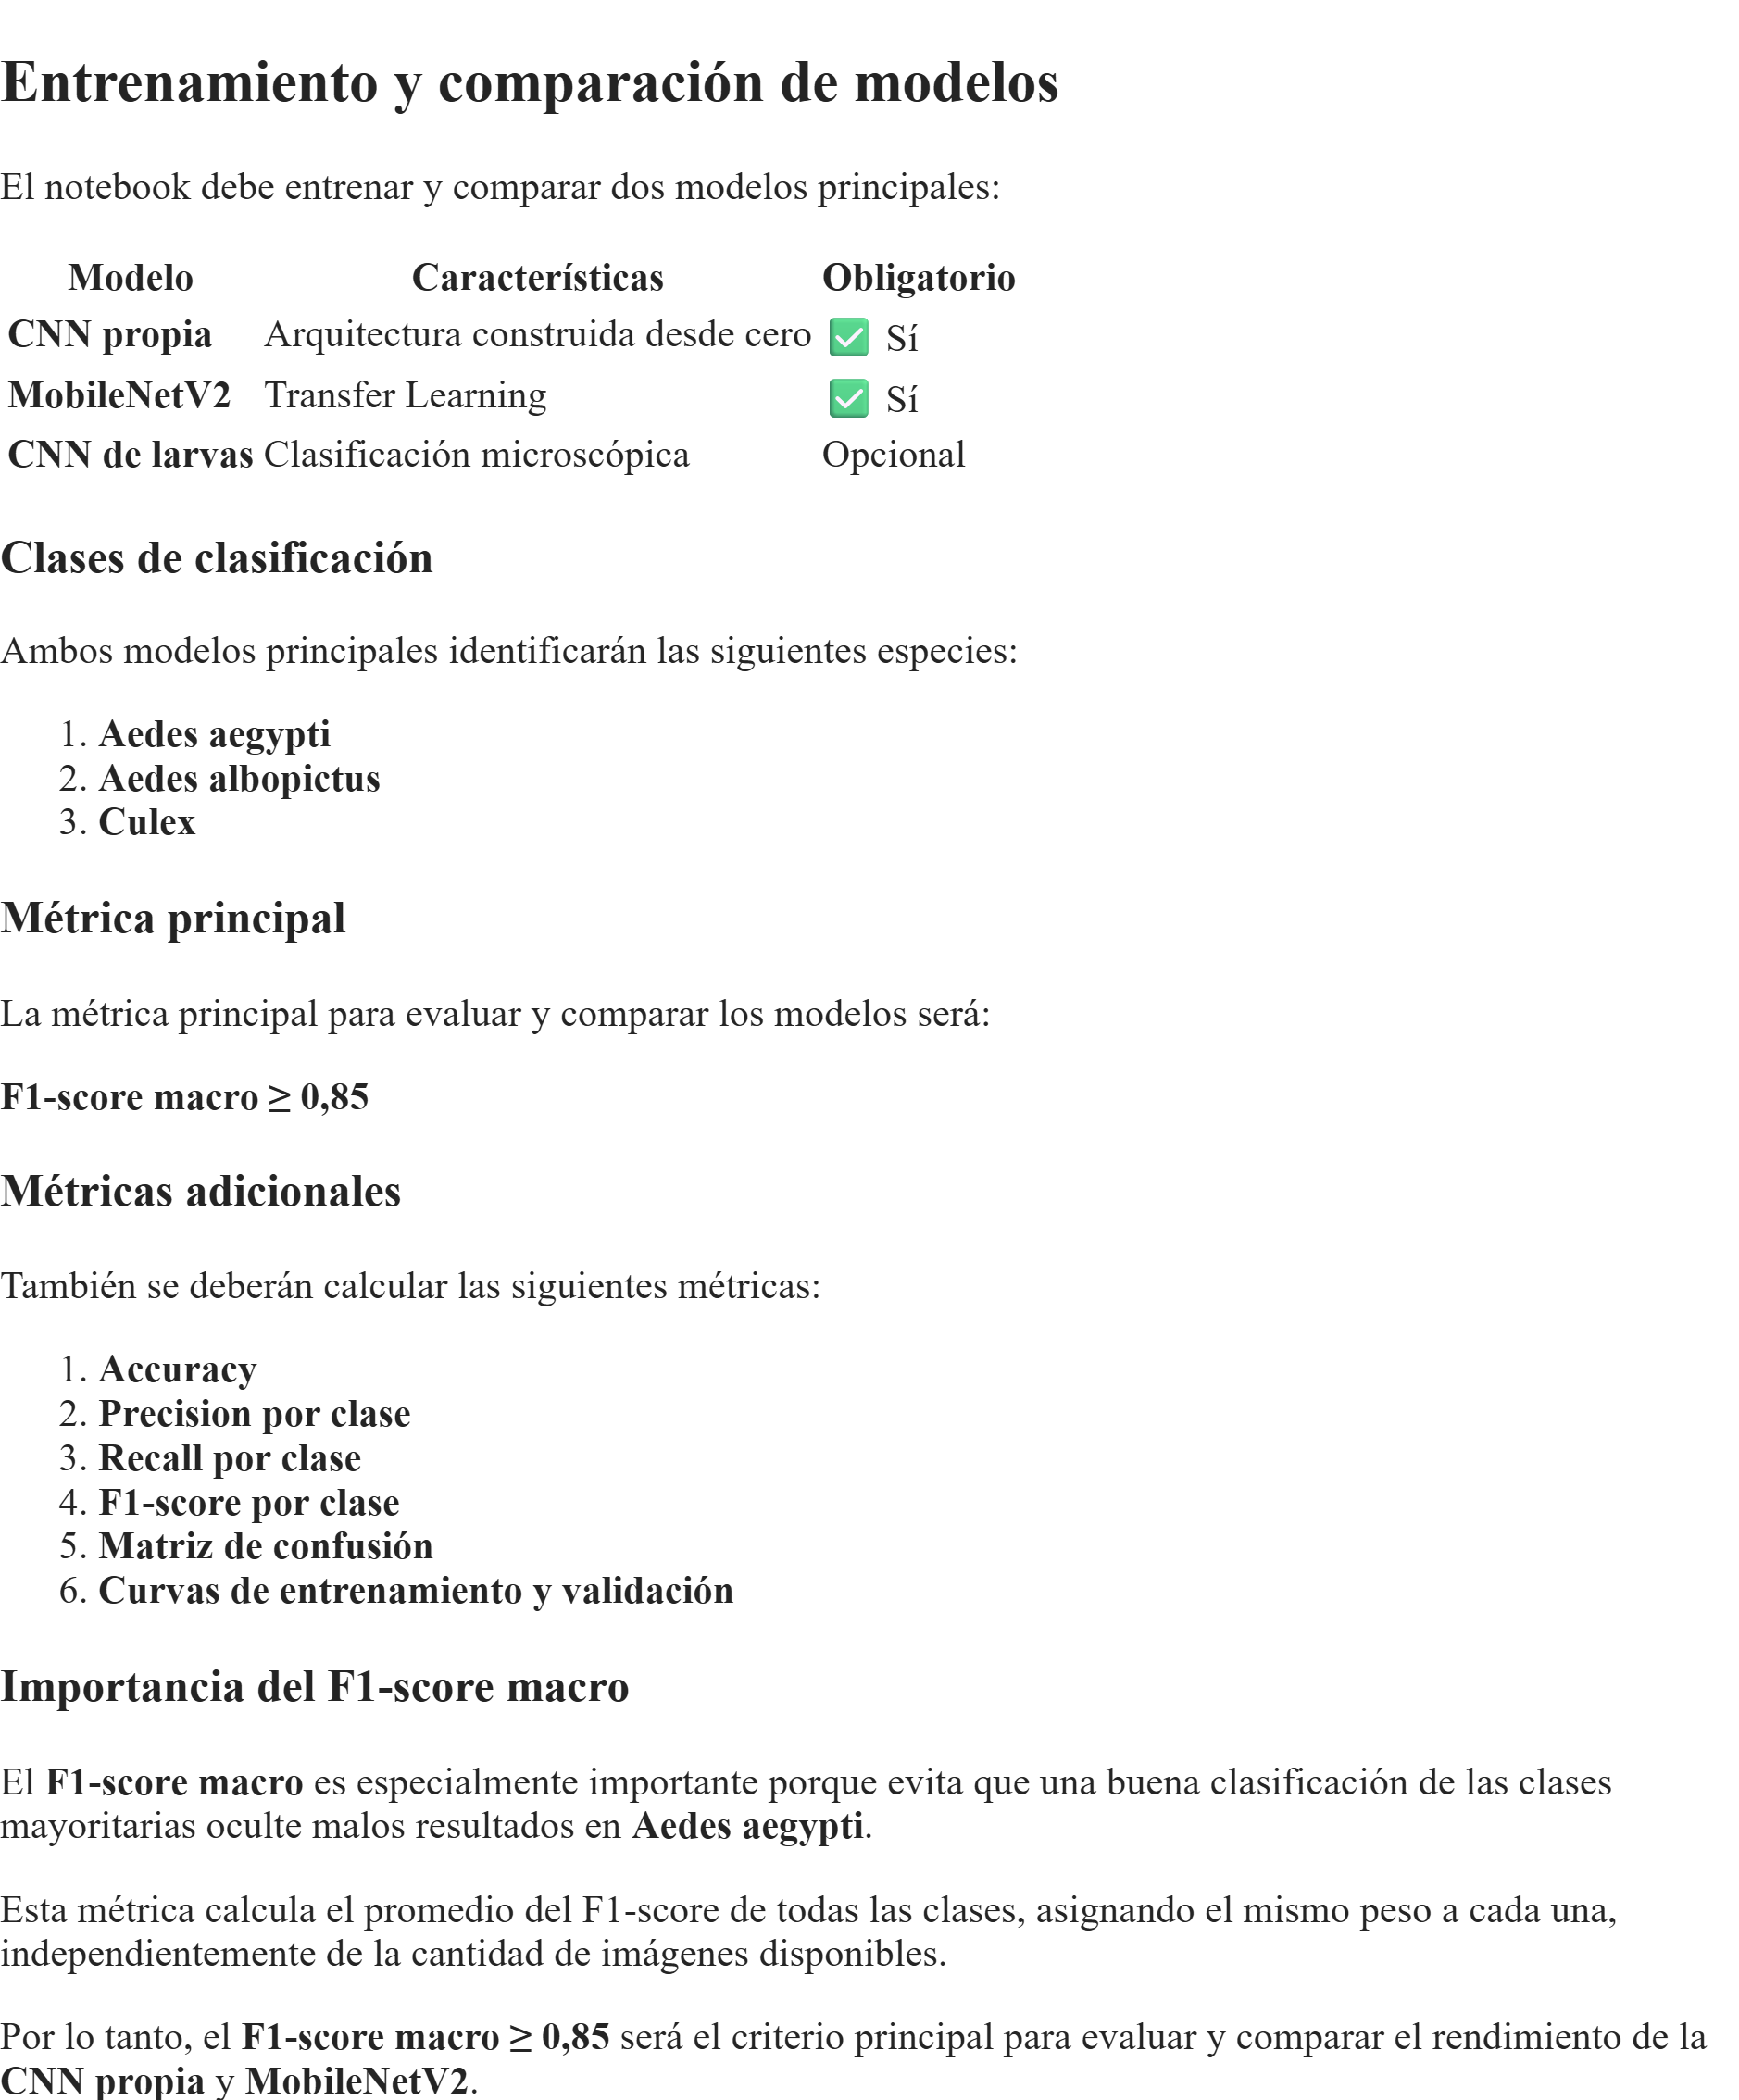
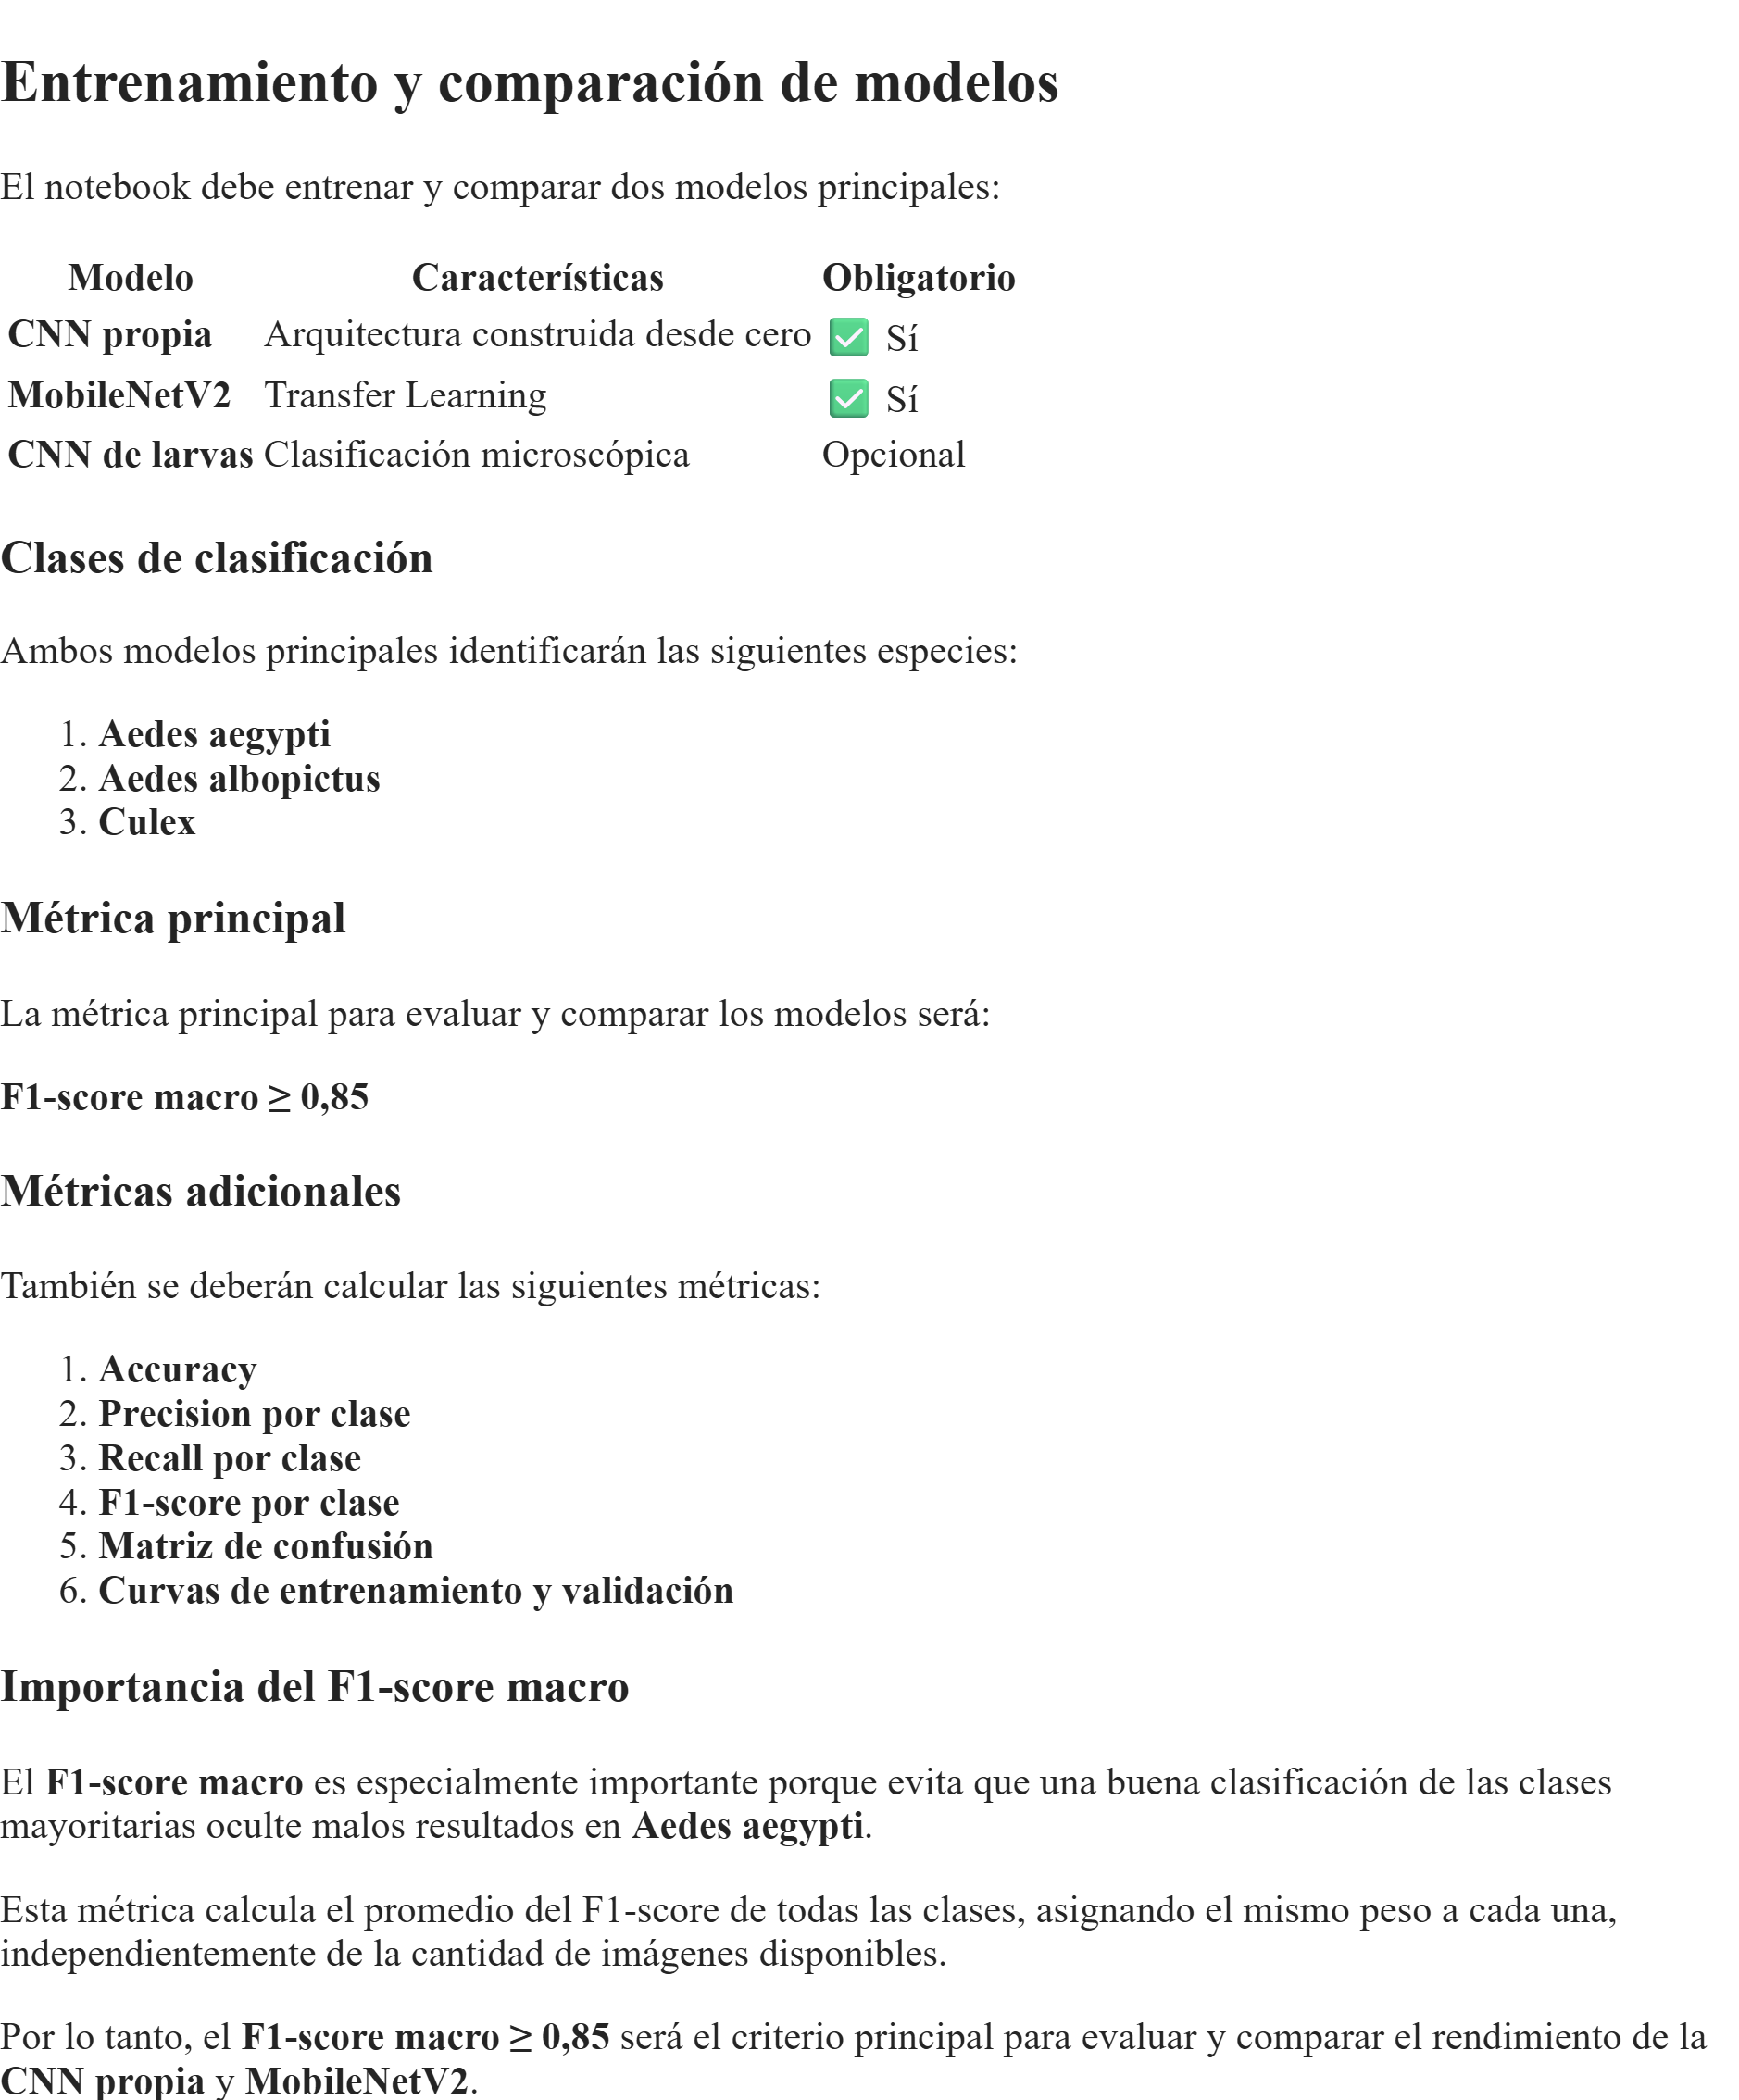

In [4]:
from pathlib import Path
import os
import random
import hashlib
import json
import re

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

import cv2

from PIL import Image, ImageOps

import tensorflow as tf

from tensorflow import keras
from tensorflow.keras import layers

from sklearn.model_selection import (
    train_test_split,
    StratifiedGroupKFold
)

from sklearn.utils.class_weight import compute_class_weight

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0
GPU: []


## CONFIGURACIÓN
### Definir parámetros generales

In [19]:
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

IMG_HEIGHT = 128
IMG_WIDTH = 128
IMG_SIZE = (IMG_HEIGHT, IMG_WIDTH)

BATCH_SIZE = 32

EPOCHS_CNN = 50
EPOCHS_MOBILENET = 30

CLASES = [
    "Aedes aegypti",
    "Aedes albopictus",
    "Culex"
]

NUM_CLASES = len(CLASES)

CLASS_TO_ID = {
    clase: indice
    for indice, clase in enumerate(CLASES)
}

ID_TO_CLASS = {
    indice: clase
    for clase, indice in CLASS_TO_ID.items()
}

print("Semilla:", SEED)
print("Tamaño de imagen:", IMG_SIZE)
print("Batch size:", BATCH_SIZE)
print("Clases:", CLASS_TO_ID)

Semilla: 42
Tamaño de imagen: (128, 128)
Batch size: 32
Clases: {'Aedes aegypti': 0, 'Aedes albopictus': 1, 'Culex': 2}


## Rutas generales del proyecto

In [20]:
PROYECTO = Path(r"C:\VectorAI\VectorIA")

RAW = PROYECTO / "data" / "raw"
PROCESSED = PROYECTO / "data" / "processed" / "cnn"
MODELS = PROYECTO / "models"

PROCESSED.mkdir(
    parents=True,
    exist_ok=True
)

MODELS.mkdir(
    parents=True,
    exist_ok=True
)

print("Proyecto:", PROYECTO)
print("Datos originales:", RAW)
print("Datos procesados:", PROCESSED)
print("Modelos:", MODELS)

assert PROYECTO.is_dir(), (
    f"No existe la carpeta del proyecto: {PROYECTO}"
)

assert RAW.is_dir(), (
    f"No existe la carpeta de datos originales: {RAW}"
)

Proyecto: C:\VectorAI\VectorIA
Datos originales: C:\VectorAI\VectorIA\data\raw
Datos procesados: C:\VectorAI\VectorIA\data\processed\cnn
Modelos: C:\VectorAI\VectorIA\models


## Inspeccionar Data raw

In [21]:
print("Contenido de RAW:\n")

for elemento in sorted(RAW.iterdir()):
    tipo = "CARPETA" if elemento.is_dir() else "ARCHIVO"
    print(f"[{tipo}] {elemento.name}")

Contenido de RAW:

[CARPETA] Dataset of Vector Mosquito Images
[CARPETA] kaggle
[CARPETA] MLMI-2024 (Mosquito Larvae Microscopic Images)
[CARPETA] Mosquito Dataset Augmented
[CARPETA] mosquito_dataset_ai_v1


## Rutas de los DataSets


In [22]:
RUTA_IEEE = (
    RAW
    / "Mosquito Dataset Augmented"
)

RUTA_MENDELEY = (
    RAW
    / "Dataset of Vector Mosquito Images"
)

RUTA_MOSQUITO_ALERT = (
    RAW
    / "mosquito_dataset_ai_v1"
)

RUTA_KAGGLE = (
    RAW
    / "kaggle"
)

RUTAS_DATASETS = {
    "IEEE": RUTA_IEEE,
    "Mendeley": RUTA_MENDELEY,
    "Mosquito Alert": RUTA_MOSQUITO_ALERT,
    "Kaggle": RUTA_KAGGLE
}

for nombre, ruta_dataset in RUTAS_DATASETS.items():
    print(
        f"{nombre:17} | "
        f"Existe: {ruta_dataset.exists()} | "
        f"Es carpeta: {ruta_dataset.is_dir()} | "
        f"{ruta_dataset}"
    )

IEEE              | Existe: True | Es carpeta: True | C:\VectorAI\VectorIA\data\raw\Mosquito Dataset Augmented
Mendeley          | Existe: True | Es carpeta: True | C:\VectorAI\VectorIA\data\raw\Dataset of Vector Mosquito Images
Mosquito Alert    | Existe: True | Es carpeta: True | C:\VectorAI\VectorIA\data\raw\mosquito_dataset_ai_v1
Kaggle            | Existe: True | Es carpeta: True | C:\VectorAI\VectorIA\data\raw\kaggle


In [23]:
rutas_faltantes = {
    nombre: ruta
    for nombre, ruta in RUTAS_DATASETS.items()
    if not ruta.is_dir()
}

if rutas_faltantes:
    for nombre, ruta in rutas_faltantes.items():
        print(f"Ruta faltante para {nombre}: {ruta}")

    raise FileNotFoundError(
        "Una o más rutas de datasets no existen."
    )

print("\nTodas las rutas principales existen.")


Todas las rutas principales existen.


## Extensiones y mapeo de clases

In [24]:
EXTENSIONES_IMAGEN = {
    ".jpg",
    ".jpeg",
    ".png",
    ".webp",
    ".bmp",
    ".tif",
    ".tiff"
}

MAPEO_CLASES = {
    # IEEE
    "aedes": "Aedes aegypti",
    "culex": "Culex",

    # Mendeley
    "aedes aegypti": "Aedes aegypti",
    "culex quinquefasciatus": "Culex",

    # Mosquito Alert
    "aegypti": "Aedes aegypti",
    "albopictus": "Aedes albopictus",

    # Variantes posibles
    "aedes albopictus": "Aedes albopictus"
}

print("Extensiones permitidas:", EXTENSIONES_IMAGEN)
print("\nMapeo de clases:")

for etiqueta_original, etiqueta_final in MAPEO_CLASES.items():
    print(
        f"{etiqueta_original:25} -> {etiqueta_final}"
    )

Extensiones permitidas: {'.png', '.jpeg', '.jpg', '.tif', '.tiff', '.webp', '.bmp'}

Mapeo de clases:
aedes                     -> Aedes aegypti
culex                     -> Culex
aedes aegypti             -> Aedes aegypti
culex quinquefasciatus    -> Culex
aegypti                   -> Aedes aegypti
albopictus                -> Aedes albopictus
aedes albopictus          -> Aedes albopictus


Las etiquetas no incluidas, como Anopheles, Culiseta y Aedes japonicus/koreicus, quedarán excluidas.

## Funció para Listar Imágenes


In [8]:
def listar_imagenes(carpeta):
    """
    Devuelve las rutas únicas de todas las imágenes
    encontradas dentro de una carpeta.
    """
    carpeta = Path(carpeta)

    if not carpeta.is_dir():
        return []

    imagenes = {
        archivo.resolve()
        for archivo in carpeta.rglob("*")
        if archivo.is_file()
        and archivo.suffix.lower() in EXTENSIONES_IMAGEN
    }

    return sorted(
        imagenes,
        key=lambda ruta: str(ruta).lower()
    )

### Clases excluidas
No incluiremos:
Anopheles.
Culiseta.
Aedes japonicus/koreicus.
Anopheles stephensi.
Estas especies no pertenecen a las tres clases objetivo.

In [26]:
def listar_imagenes(carpeta):
    """
    Devuelve las rutas únicas de todas las imágenes
    encontradas dentro de una carpeta.
    """
    carpeta = Path(carpeta)

    if not carpeta.is_dir():
        return []

    imagenes = {
        archivo.resolve()
        for archivo in carpeta.rglob("*")
        if archivo.is_file()
        and archivo.suffix.lower() in EXTENSIONES_IMAGEN
    }

    return sorted(
        imagenes,
        key=lambda ruta: str(ruta).lower()
    )

In [27]:
for nombre, ruta_dataset in RUTAS_DATASETS.items():
    cantidad = len(
        listar_imagenes(ruta_dataset)
    )

    print(
        f"{nombre:17}: "
        f"{cantidad:,} archivos de imagen"
    )

IEEE             : 1,404 archivos de imagen
Mendeley         : 2,684 archivos de imagen
Mosquito Alert   : 10,357 archivos de imagen
Kaggle           : 2,462 archivos de imagen


## Inspeccionar nombres de carpetas

In [28]:
def obtener_carpetas_unicas(ruta_dataset):
    ruta_dataset = Path(ruta_dataset)

    carpetas = {
        carpeta.name
        for carpeta in ruta_dataset.rglob("*")
        if carpeta.is_dir()
    }

    return sorted(
        carpetas,
        key=str.lower
    )


for nombre, ruta_dataset in RUTAS_DATASETS.items():
    print("\n" + "=" * 60)
    print(nombre)
    print("=" * 60)

    carpetas = obtener_carpetas_unicas(
        ruta_dataset
    )

    for carpeta in carpetas[:50]:
        print(carpeta)

    if len(carpetas) > 50:
        print(
            f"... y {len(carpetas) - 50} carpetas adicionales"
        )


IEEE
Aedes
Culex

Mendeley
Aedes Aegypti
Anopheles Stephensi
Culex Quinquefasciatus
Mosquito Images Augmented
Mosquito Images Original
Original Images Mendeley

Mosquito Alert
images
labels

Kaggle
aegypti
aegypti_0
aegypti_0_testing
aegypti_180
aegypti_180_testing
aegypti_270
aegypti_270_testing
aegypti_90
aegypti_90_testing
albopictus
albopictus_0


## Iniciar el Inventario

In [44]:
registros = []
errores_inventario = []

## Función para registrar imágenes

In [45]:
def registrar_imagen(
    filepath,
    source_dataset,
    original_label,
    bbox=None,
    bbox_valid=None,
    group_id=None
):
    filepath = Path(filepath)

    if not filepath.is_file():
        errores_inventario.append({
            "source_dataset": source_dataset,
            "filepath": str(filepath),
            "error": "El archivo no existe"
        })

        return False

    if filepath.suffix.lower() not in EXTENSIONES_IMAGEN:
        errores_inventario.append({
            "source_dataset": source_dataset,
            "filepath": str(filepath),
            "error": "Extensión no admitida"
        })

        return False

    original_label_normalized = (
        str(original_label)
        .strip()
        .lower()
    )

    class_name = MAPEO_CLASES.get(
        original_label_normalized
    )

    if class_name is None:
        return False

    bbox_x1 = np.nan
    bbox_y1 = np.nan
    bbox_x2 = np.nan
    bbox_y2 = np.nan

    if bbox is not None:
        if len(bbox) != 4:
            errores_inventario.append({
                "source_dataset": source_dataset,
                "filepath": str(filepath),
                "error": f"Bounding box inválida: {bbox}"
            })

            return False

        bbox_x1 = int(bbox[0])
        bbox_y1 = int(bbox[1])
        bbox_x2 = int(bbox[2])
        bbox_y2 = int(bbox[3])

    if bbox_valid is None:
        bbox_valid = bbox is not None

    if group_id is None:
        group_id = (
            f"{source_dataset}_{filepath.stem}"
        )

    registros.append({
        "filepath": str(filepath.resolve()),
        "filename": filepath.name,
        "extension": filepath.suffix.lower(),
        "source_dataset": source_dataset,
        "original_label": str(original_label),
        "original_label_normalized": (
            original_label_normalized
        ),
        "class_name": class_name,
        "class_id": CLASS_TO_ID[class_name],
        "group_id": str(group_id),
        "bbox_x1": bbox_x1,
        "bbox_y1": bbox_y1,
        "bbox_x2": bbox_x2,
        "bbox_y2": bbox_y2,
        "has_bbox": bbox is not None,
        "bbox_valid": bool(bbox_valid)
    })

    return True

## Cargador IEEE

In [46]:
def cargar_ieee(ruta_ieee):
    ruta_ieee = Path(ruta_ieee)

    if not ruta_ieee.is_dir():
        raise FileNotFoundError(
            f"No existe IEEE: {ruta_ieee}"
        )

    conteos = {
        "Aedes": 0,
        "Culex": 0
    }

    sin_clase = []

    for archivo in listar_imagenes(ruta_ieee):
        partes = [
            parte.lower()
            for parte in archivo.parts
        ]

        if any(
            "culex" in parte
            for parte in partes
        ):
            etiqueta = "Culex"

        elif any(
            "aedes" in parte
            for parte in partes
        ):
            etiqueta = "Aedes"

        else:
            sin_clase.append(str(archivo))
            continue

        agregado = registrar_imagen(
            filepath=archivo,
            source_dataset="IEEE",
            original_label=etiqueta,
            group_id=f"IEEE_{archivo.stem}"
        )

        if agregado:
            conteos[etiqueta] += 1

    print("\nIEEE")
    print(
        "Aedes -> Aedes aegypti:",
        conteos["Aedes"]
    )
    print("Culex:", conteos["Culex"])
    print("Total útil:", sum(conteos.values()))
    print("Imágenes sin identificar:", len(sin_clase))

    return {
        "conteos": conteos,
        "sin_clase": sin_clase
    }

In [47]:
registros.clear()
errores_inventario.clear()

resultado_ieee = cargar_ieee(
    RUTA_IEEE
)

print(
    "\nRegistros después de IEEE:",
    len(registros)
)


IEEE
Aedes -> Aedes aegypti: 810
Culex: 594
Total útil: 1404
Imágenes sin identificar: 0

Registros después de IEEE: 1404


## Cargador Mendeley

In [48]:
def cargar_mendeley(ruta_mendeley):
    """
    Carga únicamente las imágenes originales de Mendeley.

    Excluye:
    - Mosquito Images Augmented
    - Anopheles stephensi

    Incluye:
    - Aedes aegypti
    - Culex quinquefasciatus
    """

    ruta_mendeley = Path(ruta_mendeley)

    if not ruta_mendeley.is_dir():
        raise FileNotFoundError(
            f"No existe Mendeley: {ruta_mendeley}"
        )

    # Carpeta que contiene las fotografías originales.
    carpeta_originales = (
        ruta_mendeley
        / "Mosquito Images Original"
        / "Original Images Mendeley"
    )

    if not carpeta_originales.is_dir():
        raise FileNotFoundError(
            "No se encontró la carpeta de imágenes originales: "
            f"{carpeta_originales}"
        )

    configuracion = {
        "Aedes Aegypti": "Aedes aegypti",
        "Culex Quinquefasciatus": "Culex quinquefasciatus"
    }

    conteos = {
        "Aedes aegypti": 0,
        "Culex quinquefasciatus": 0
    }

    for nombre_carpeta, etiqueta in configuracion.items():

        carpeta_especie = (
            carpeta_originales
            / nombre_carpeta
        )

        if not carpeta_especie.is_dir():
            raise FileNotFoundError(
                f"No existe la carpeta: {carpeta_especie}"
            )

        imagenes = listar_imagenes(
            carpeta_especie
        )

        for archivo in imagenes:

            agregado = registrar_imagen(
                filepath=archivo,
                source_dataset="Mendeley",
                original_label=etiqueta,
                group_id=f"Mendeley_{archivo.stem}"
            )

            if agregado:
                conteos[etiqueta] += 1

    total = sum(conteos.values())

    print("\nMENDELEY - IMÁGENES ORIGINALES")
    print("=" * 45)

    print(
        "Aedes aegypti:",
        conteos["Aedes aegypti"]
    )

    print(
        "Culex quinquefasciatus:",
        conteos["Culex quinquefasciatus"]
    )

    print("Total útil:", total)

    print(
        "Imágenes aumentadas:",
        "excluidas del inventario"
    )

    return {
        "conteos": conteos,
        "total": total,
        "tipo": "originales"
    }

In [54]:
# Reiniciar el inventario temporal.
registros.clear()
errores_inventario.clear()

# Cargar IEEE.
resultado_ieee = cargar_ieee(
    RUTA_IEEE
)

# Cargar únicamente originales de Mendeley.
resultado_mendeley = cargar_mendeley(
    RUTA_MENDELEY
)

print("\n" + "=" * 50)
print("RESUMEN ACUMULADO")
print("=" * 50)

print(
    "Registros IEEE + Mendeley:",
    len(registros)
)


IEEE
Aedes -> Aedes aegypti: 810
Culex: 594
Total útil: 1404
Imágenes sin identificar: 0

MENDELEY - IMÁGENES ORIGINALES
Aedes aegypti: 15
Culex quinquefasciatus: 20
Total útil: 35
Imágenes aumentadas: excluidas del inventario

RESUMEN ACUMULADO
Registros IEEE + Mendeley: 1439


In [55]:
df_temporal = pd.DataFrame(registros)

print("DISTRIBUCIÓN ACTUAL")
print("=" * 50)

display(
    pd.crosstab(
        df_temporal["source_dataset"],
        df_temporal["class_name"]
    )
)

# Verificar que no se hayan incluido imágenes aumentadas.
mendeley_registros = df_temporal[
    df_temporal["source_dataset"] == "Mendeley"
]

rutas_aumentadas = (
    mendeley_registros["filepath"]
    .str.contains(
        "Mosquito Images Augmented",
        case=False,
        regex=False
    )
)

assert not rutas_aumentadas.any(), (
    "Se encontraron imágenes aumentadas de Mendeley."
)

assert len(mendeley_registros) == 35, (
    "Mendeley debería aportar 35 imágenes originales útiles."
)

print("\nValidación correcta:")
print("- Mendeley contiene 35 imágenes originales útiles.")
print("- No se incluyeron imágenes aumentadas.")

DISTRIBUCIÓN ACTUAL


class_name,Aedes aegypti,Culex
source_dataset,,
IEEE,810,594
Mendeley,15,20



Validación correcta:
- Mendeley contiene 35 imágenes originales útiles.
- No se incluyeron imágenes aumentadas.


In [57]:
# Limpiar únicamente el inventario temporal
registros.clear()
errores_inventario.clear()

# Volver a cargar IEEE
resultado_ieee = cargar_ieee(
    RUTA_IEEE
)

# Volver a cargar Mendeley
resultado_mendeley = cargar_mendeley(
    RUTA_MENDELEY
)

print("\n" + "=" * 50)
print("VALIDACIÓN FINAL")
print("=" * 50)

print("Total de registros:", len(registros))

assert len(registros) == 1439, (
    f"Se esperaban 1439 registros, "
    f"pero se encontraron {len(registros)}"
)

print("✅ IEEE y Mendeley cargados correctamente.")


IEEE
Aedes -> Aedes aegypti: 810
Culex: 594
Total útil: 1404
Imágenes sin identificar: 0

MENDELEY - IMÁGENES ORIGINALES
Aedes aegypti: 15
Culex quinquefasciatus: 20
Total útil: 35
Imágenes aumentadas: excluidas del inventario

VALIDACIÓN FINAL
Total de registros: 1439
✅ IEEE y Mendeley cargados correctamente.


In [58]:
df_temporal = pd.DataFrame(registros)

print("Total:", len(df_temporal))

print(
    "Rutas repetidas:",
    df_temporal["filepath"].duplicated().sum()
)

display(
    pd.crosstab(
        df_temporal["source_dataset"],
        df_temporal["class_name"]
    )
)

Total: 1439
Rutas repetidas: 0


class_name,Aedes aegypti,Culex
source_dataset,,
IEEE,810,594
Mendeley,15,20


## Buscar el archivo de anotaciones

In [59]:
def buscar_archivo_unico(carpeta_base, nombre_archivo):

    coincidencias = list(
        Path(carpeta_base).rglob(nombre_archivo)
    )

    if not coincidencias:
        raise FileNotFoundError(
            f"No se encontró {nombre_archivo} "
            f"dentro de {carpeta_base}"
        )

    if len(coincidencias) > 1:
        raise ValueError(
            f"Se encontraron varios archivos "
            f"{nombre_archivo}: {coincidencias}"
        )

    return coincidencias[0]


RUTA_ANNOTATIONS = buscar_archivo_unico(
    RUTA_MOSQUITO_ALERT,
    "annotations.csv"
)

print("Archivo encontrado:")
print(RUTA_ANNOTATIONS)

Archivo encontrado:
C:\VectorAI\VectorIA\data\raw\mosquito_dataset_ai_v1\labels\annotations.csv


## Inspeccionar las anotaciones

In [60]:
anotaciones = pd.read_csv(
    RUTA_ANNOTATIONS
)

print("Cantidad de anotaciones:", len(anotaciones))

print("\nColumnas encontradas:")
print(anotaciones.columns.tolist())

print("\nPrimeras 10 anotaciones:")
display(anotaciones.head(10))

print("\nDistribución de etiquetas:")
display(
    anotaciones["class_label"].value_counts()
)

Cantidad de anotaciones: 10357

Columnas encontradas:
['img_fName', 'img_w', 'img_h', 'bbx_xtl', 'bbx_ytl', 'bbx_xbr', 'bbx_ybr', 'class_label']

Primeras 10 anotaciones:


,img_fName,img_w,img_h,bbx_xtl,bbx_ytl,bbx_xbr,bbx_ybr,class_label
0,train_00000.jpeg,2448,3264,1301,1546,1641,2096,albopictus
1,train_00001.jpeg,3024,4032,900,1897,1950,2990,albopictus
2,train_00002.jpeg,768,1024,220,58,659,808,albopictus
3,train_00003.jpeg,3456,4608,1169,2364,1586,2826,albopictus
4,train_00004.jpeg,1024,1365,129,231,697,1007,culex
5,train_00005.jpeg,1152,2560,198,798,954,1351,albopictus
6,train_00006.jpeg,3072,4080,1104,1030,2458,2911,anopheles
7,train_00007.jpeg,2128,4608,248,728,2049,1992,albopictus
8,train_00008.jpeg,4000,2250,1768,899,2414,1591,albopictus
9,train_00009.jpeg,768,1024,180,140,683,744,albopictus



Distribución de etiquetas:


class_label
albopictus            4612
culex                 4563
culiseta               622
japonicus-koreicus     429
anopheles               84
aegypti                 47
Name: count, dtype: int64

## Crear el cargador de Mosquito Alert

Esta función:

Localiza la carpeta images.

Relaciona cada fotografía con su anotación.

Conserva las etiquetas.

Verifica las bounding boxes.

Registra únicamente las tres clases de VectorIA.

Reporta imágenes faltantes y cajas inválidas.


In [61]:
def cargar_mosquito_alert(ruta_mosquito_alert):

    ruta_mosquito_alert = Path(
        ruta_mosquito_alert
    )

    if not ruta_mosquito_alert.is_dir():
        raise FileNotFoundError(
            f"No existe Mosquito Alert: {ruta_mosquito_alert}"
        )

    csv_anotaciones = buscar_archivo_unico(
        ruta_mosquito_alert,
        "annotations.csv"
    )

    anotaciones = pd.read_csv(
        csv_anotaciones
    )

    columnas_requeridas = {
        "img_fName",
        "img_w",
        "img_h",
        "bbx_xtl",
        "bbx_ytl",
        "bbx_xbr",
        "bbx_ybr",
        "class_label"
    }

    faltantes = (
        columnas_requeridas
        - set(anotaciones.columns)
    )

    if faltantes:
        raise ValueError(
            f"Faltan columnas: {sorted(faltantes)}"
        )

    carpetas_images = [
        carpeta
        for carpeta in ruta_mosquito_alert.rglob("*")
        if carpeta.is_dir()
        and carpeta.name.lower() == "images"
    ]

    if len(carpetas_images) != 1:
        raise ValueError(
            "Se esperaba una sola carpeta images. "
            f"Encontradas: {carpetas_images}"
        )

    carpeta_images = carpetas_images[0]

    archivos_por_nombre = {}

    for archivo in listar_imagenes(carpeta_images):
        archivos_por_nombre.setdefault(
            archivo.name,
            []
        ).append(archivo)

    clases_utiles = {
        "aegypti",
        "albopictus",
        "culex"
    }

    conteos = {
        "aegypti": 0,
        "albopictus": 0,
        "culex": 0
    }

    sin_imagen = []
    nombres_ambiguos = []
    cajas_invalidas = []

    for _, fila in anotaciones.iterrows():

        etiqueta = str(
            fila["class_label"]
        ).strip().lower()

        if etiqueta not in clases_utiles:
            continue

        nombre_imagen = str(
            fila["img_fName"]
        ).strip()

        coincidencias = archivos_por_nombre.get(
            nombre_imagen,
            []
        )

        if len(coincidencias) == 0:
            sin_imagen.append(nombre_imagen)
            continue

        if len(coincidencias) > 1:
            nombres_ambiguos.append(nombre_imagen)
            continue

        archivo = coincidencias[0]

        coordenadas = [
            "bbx_xtl",
            "bbx_ytl",
            "bbx_xbr",
            "bbx_ybr",
            "img_w",
            "img_h"
        ]

        if fila[coordenadas].isna().any():
            cajas_invalidas.append({
                "filename": nombre_imagen,
                "motivo": "Coordenadas faltantes"
            })
            bbox = None
            bbox_valida = False

        else:
            x1 = int(fila["bbx_xtl"])
            y1 = int(fila["bbx_ytl"])
            x2 = int(fila["bbx_xbr"])
            y2 = int(fila["bbx_ybr"])

            ancho = int(fila["img_w"])
            alto = int(fila["img_h"])

            bbox_valida = (
                0 <= x1 < x2 <= ancho
                and
                0 <= y1 < y2 <= alto
            )

            if bbox_valida:
                bbox = (x1, y1, x2, y2)

            else:
                bbox = None

                cajas_invalidas.append({
                    "filename": nombre_imagen,
                    "class_label": etiqueta,
                    "img_w": ancho,
                    "img_h": alto,
                    "bbox_x1": x1,
                    "bbox_y1": y1,
                    "bbox_x2": x2,
                    "bbox_y2": y2
                })

        agregado = registrar_imagen(
            filepath=archivo,
            source_dataset="Mosquito Alert",
            original_label=etiqueta,
            bbox=bbox,
            bbox_valid=bbox_valida,
            group_id=f"MosquitoAlert_{archivo.stem}"
        )

        if agregado:
            conteos[etiqueta] += 1

    print("\nMOSQUITO ALERT")
    print("=" * 50)

    print("Aedes aegypti:", conteos["aegypti"])
    print("Aedes albopictus:", conteos["albopictus"])
    print("Culex:", conteos["culex"])

    print(
        "Total útil:",
        sum(conteos.values())
    )

    print(
        "Anotaciones sin imagen:",
        len(sin_imagen)
    )

    print(
        "Nombres ambiguos:",
        len(nombres_ambiguos)
    )

    print(
        "Cajas inválidas:",
        len(cajas_invalidas)
    )

    return {
        "conteos": conteos,
        "sin_imagen": sin_imagen,
        "nombres_ambiguos": nombres_ambiguos,
        "cajas_invalidas": cajas_invalidas
    }

## Ejecutar Mosquito Alert
#### verificaremos que tenemos las 1.439 imágenes correctas.

In [62]:
print("Registros antes de Mosquito Alert:", len(registros))

assert len(registros) == 1439, (
    "Antes de cargar Mosquito Alert deben existir "
    "1439 registros de IEEE y Mendeley."
)

resultado_mosquito_alert = cargar_mosquito_alert(
    RUTA_MOSQUITO_ALERT
)

print("\n" + "=" * 50)
print("RESUMEN ACUMULADO")
print("=" * 50)

print("Registros acumulados:", len(registros))

Registros antes de Mosquito Alert: 1439

MOSQUITO ALERT
Aedes aegypti: 47
Aedes albopictus: 4612
Culex: 4563
Total útil: 9222
Anotaciones sin imagen: 0
Nombres ambiguos: 0
Cajas inválidas: 3

RESUMEN ACUMULADO
Registros acumulados: 10661


#### Revisar las cajas inválidas

In [63]:
df_cajas_invalidas = pd.DataFrame(
    resultado_mosquito_alert["cajas_invalidas"]
)

print(
    "Cantidad de cajas inválidas:",
    len(df_cajas_invalidas)
)

if not df_cajas_invalidas.empty:
    display(df_cajas_invalidas)
else:
    print("No se encontraron cajas inválidas.")

Cantidad de cajas inválidas: 3


,filename,class_label,img_w,img_h,bbox_x1,bbox_y1,bbox_x2,bbox_y2
0,train_09004.jpeg,culex,1024,1365,435,233,1159,650
1,train_10156.jpeg,albopictus,1024,2272,1070,512,1312,845
2,train_10160.jpeg,culex,1816,4032,1755,522,2345,964


#### Verificar el inventario acumulado

In [64]:
df_temporal = pd.DataFrame(registros)

print("Total acumulado:", len(df_temporal))

print("\nDistribución por dataset:")

display(
    df_temporal["source_dataset"].value_counts()
)

print("\nDistribución por clase:")

display(
    pd.crosstab(
        df_temporal["source_dataset"],
        df_temporal["class_name"]
    )
)

print("\nRutas repetidas:")

print(
    df_temporal["filepath"].duplicated().sum()
)

Total acumulado: 10661

Distribución por dataset:


source_dataset
Mosquito Alert    9222
IEEE              1404
Mendeley            35
Name: count, dtype: int64


Distribución por clase:


class_name,Aedes aegypti,Aedes albopictus,Culex
source_dataset,,,
IEEE,810,0,594
Mendeley,15,0,20
Mosquito Alert,47,4612,4563



Rutas repetidas:
0


## Crear identificadores de grupo para Kaggle

In [65]:
def obtener_grupo_kaggle(nombre_archivo):

    stem = (
        Path(nombre_archivo)
        .stem
        .lower()
        .strip()
    )

    # Eliminar sufijos como " - Copy".
    stem = re.sub(
        r"\s*-\s*copy(?:\s*\(\d+\))?$",
        "",
        stem,
        flags=re.IGNORECASE
    )

    # Eliminar una letra final a, b, c o d
    # cuando aparece después de un número.
    stem = re.sub(
        r"(?<=\d)[a-d]$",
        "",
        stem
    )

    return stem

In [66]:
ejemplos = [
    "aegypti100a.jpg",
    "aegypti100b.jpg",
    "aegypti100c.jpg",
    "albopictus25d.jpg",
    "aegypti29b - Copy.jpg"
]

for nombre in ejemplos:
    print(
        nombre,
        "->",
        obtener_grupo_kaggle(nombre)
    )

aegypti100a.jpg -> aegypti100
aegypti100b.jpg -> aegypti100
aegypti100c.jpg -> aegypti100
albopictus25d.jpg -> albopictus25
aegypti29b - Copy.jpg -> aegypti29


## Crear el cargador de Kaggle

In [67]:
def cargar_kaggle(ruta_kaggle):

    ruta_kaggle = Path(ruta_kaggle)

    if not ruta_kaggle.is_dir():
        raise FileNotFoundError(
            f"No existe Kaggle: {ruta_kaggle}"
        )

    conteos = {
        "aegypti": 0,
        "albopictus": 0
    }

    sin_clase = []

    for archivo in listar_imagenes(ruta_kaggle):

        # Utilizar solamente las carpetas
        # relativas al dataset Kaggle.
        partes = [
            parte.strip().lower()
            for parte in archivo.relative_to(
                ruta_kaggle
            ).parts[:-1]
        ]

        if "albopictus" in partes:
            etiqueta = "albopictus"

        elif "aegypti" in partes:
            etiqueta = "aegypti"

        else:
            sin_clase.append(str(archivo))
            continue

        grupo_base = obtener_grupo_kaggle(
            archivo.name
        )

        agregado = registrar_imagen(
            filepath=archivo,
            source_dataset="Kaggle",
            original_label=etiqueta,
            group_id=(
                f"Kaggle_{etiqueta}_{grupo_base}"
            )
        )

        if agregado:
            conteos[etiqueta] += 1

    print("\nKAGGLE")
    print("=" * 50)

    print(
        "Aedes aegypti:",
        conteos["aegypti"]
    )

    print(
        "Aedes albopictus:",
        conteos["albopictus"]
    )

    print(
        "Total útil:",
        sum(conteos.values())
    )

    print(
        "Imágenes sin clase:",
        len(sin_clase)
    )

    return {
        "conteos": conteos,
        "sin_clase": sin_clase
    }

## Ejecutar Kaggle

In [68]:
print(
    "Registros antes de Kaggle:",
    len(registros)
)

assert len(registros) == 10661, (
    "Se esperaban 10661 registros antes "
    "de incorporar Kaggle."
)

resultado_kaggle = cargar_kaggle(
    RUTA_KAGGLE
)

print("\n" + "=" * 50)
print("RESUMEN ACUMULADO")
print("=" * 50)

print(
    "Total de registros:",
    len(registros)
)

Registros antes de Kaggle: 10661

KAGGLE
Aedes aegypti: 2403
Aedes albopictus: 59
Total útil: 2462
Imágenes sin clase: 0

RESUMEN ACUMULADO
Total de registros: 13123


## Crear el DataFrame completo

In [70]:
df = pd.DataFrame(registros)

if df.empty:
    raise RuntimeError(
        "El inventario está vacío."
    )

print("=" * 50)
print("INVENTARIO MAESTRO VECTOR-IA")
print("=" * 50)

print(
    "Total de imágenes:",
    len(df)
)

print(
    "Columnas:",
    len(df.columns)
)

display(
    df.head(10)
)

INVENTARIO MAESTRO VECTOR-IA
Total de imágenes: 13123
Columnas: 15


,filepath,filename,extension,source_dataset,original_label,original_label_normalized,class_name,class_id,group_id,bbox_x1,bbox_y1,bbox_x2,bbox_y2,has_bbox,bbox_valid
0,C:\VectorAI\VectorIA\data\raw\Mosquito Dataset...,Aedes1.jpg,.jpg,IEEE,Aedes,aedes,Aedes aegypti,0,IEEE_Aedes1,NaN,NaN,NaN,NaN,False,False
1,C:\VectorAI\VectorIA\data\raw\Mosquito Dataset...,Aedes10.jpg,.jpg,IEEE,Aedes,aedes,Aedes aegypti,0,IEEE_Aedes10,NaN,NaN,NaN,NaN,False,False
2,C:\VectorAI\VectorIA\data\raw\Mosquito Dataset...,Aedes10_add0.jpg,.jpg,IEEE,Aedes,aedes,Aedes aegypti,0,IEEE_Aedes10_add0,NaN,NaN,NaN,NaN,False,False
3,C:\VectorAI\VectorIA\data\raw\Mosquito Dataset...,Aedes10_add1.jpg,.jpg,IEEE,Aedes,aedes,Aedes aegypti,0,IEEE_Aedes10_add1,NaN,NaN,NaN,NaN,False,False
4,C:\VectorAI\VectorIA\data\raw\Mosquito Dataset...,Aedes10_add2.jpg,.jpg,IEEE,Aedes,aedes,Aedes aegypti,0,IEEE_Aedes10_add2,NaN,NaN,NaN,NaN,False,False
5,C:\VectorAI\VectorIA\data\raw\Mosquito Dataset...,Aedes10_add3.jpg,.jpg,IEEE,Aedes,aedes,Aedes aegypti,0,IEEE_Aedes10_add3,NaN,NaN,NaN,NaN,False,False
6,C:\VectorAI\VectorIA\data\raw\Mosquito Dataset...,Aedes10_add4.jpg,.jpg,IEEE,Aedes,aedes,Aedes aegypti,0,IEEE_Aedes10_add4,NaN,NaN,NaN,NaN,False,False
7,C:\VectorAI\VectorIA\data\raw\Mosquito Dataset...,Aedes10_add5.jpg,.jpg,IEEE,Aedes,aedes,Aedes aegypti,0,IEEE_Aedes10_add5,NaN,NaN,NaN,NaN,False,False
8,C:\VectorAI\VectorIA\data\raw\Mosquito Dataset...,Aedes10_add6.jpg,.jpg,IEEE,Aedes,aedes,Aedes aegypti,0,IEEE_Aedes10_add6,NaN,NaN,NaN,NaN,False,False
9,C:\VectorAI\VectorIA\data\raw\Mosquito Dataset...,Aedes10_add7.jpg,.jpg,IEEE,Aedes,aedes,Aedes aegypti,0,IEEE_Aedes10_add7,NaN,NaN,NaN,NaN,False,False


## Distribucion por especie

In [71]:
distribucion_clases = (
    df["class_name"]
    .value_counts()
    .reindex(
        CLASES,
        fill_value=0
    )
)

tabla_clases = (
    distribucion_clases
    .rename_axis("Clase")
    .reset_index(name="Cantidad")
)

tabla_clases["Porcentaje (%)"] = (
    tabla_clases["Cantidad"]
    / len(df)
    * 100
).round(2)

display(tabla_clases)

,Clase,Cantidad,Porcentaje (%)
0,Aedes aegypti,3275,24.96
1,Aedes albopictus,4671,35.59
2,Culex,5177,39.45


## Distribución por DataSet

In [72]:
tabla_fuentes = pd.crosstab(
    df["source_dataset"],
    df["class_name"]
)

tabla_fuentes = tabla_fuentes.reindex(
    columns=CLASES,
    fill_value=0
)

tabla_fuentes["Total"] = (
    tabla_fuentes.sum(axis=1)
)

display(tabla_fuentes)

class_name,Aedes aegypti,Aedes albopictus,Culex,Total
source_dataset,,,,
IEEE,810,0,594,1404
Kaggle,2403,59,0,2462
Mendeley,15,0,20,35
Mosquito Alert,47,4612,4563,9222


## Verificar errores

In [73]:
print("=" * 50)
print("VALIDACIÓN DEL INVENTARIO")
print("=" * 50)

rutas_existentes = df["filepath"].map(
    lambda ruta: Path(ruta).is_file()
)

print(
    "Rutas inexistentes:",
    int((~rutas_existentes).sum())
)

print(
    "Rutas repetidas:",
    int(df["filepath"].duplicated().sum())
)

print(
    "Etiquetas vacías:",
    int(df["class_name"].isna().sum())
)

print(
    "Class ID vacíos:",
    int(df["class_id"].isna().sum())
)

print(
    "Group ID vacíos:",
    int(df["group_id"].isna().sum())
)

print(
    "Fuentes registradas:",
    sorted(df["source_dataset"].unique())
)

print(
    "Clases registradas:",
    sorted(df["class_name"].unique())
)

VALIDACIÓN DEL INVENTARIO
Rutas inexistentes: 0
Rutas repetidas: 0
Etiquetas vacías: 0
Class ID vacíos: 0
Group ID vacíos: 0
Fuentes registradas: ['IEEE', 'Kaggle', 'Mendeley', 'Mosquito Alert']
Clases registradas: ['Aedes aegypti', 'Aedes albopictus', 'Culex']


## Comprobaciones

In [74]:
assert rutas_existentes.all(), (
    "Existen rutas de imágenes inválidas."
)

assert df["class_name"].notna().all(), (
    "Existen etiquetas vacías."
)

assert df["class_id"].notna().all(), (
    "Existen identificadores de clase vacíos."
)

assert df["group_id"].notna().all(), (
    "Existen identificadores de grupo vacíos."
)

assert set(df["class_name"].unique()) == set(CLASES), (
    "No están presentes las tres clases esperadas."
)

assert df["class_id"].between(
    0,
    NUM_CLASES - 1
).all(), (
    "Existen identificadores de clase inválidos."
)

print("\nValidaciones básicas correctas.")


Validaciones básicas correctas.


## Verificar bounding boxes

In [75]:
resumen_bbox = (
    df.groupby("source_dataset")
    .agg(
        imagenes=("filepath", "size"),
        con_bbox=("has_bbox", "sum"),
        bbox_validas=("bbox_valid", "sum")
    )
)

display(resumen_bbox)

,imagenes,con_bbox,bbox_validas
source_dataset,,,
IEEE,1404,0,0
Kaggle,2462,0,0
Mendeley,35,0,0
Mosquito Alert,9222,9219,9219


## Revisar Grupos de Kaggle

In [76]:
df_kaggle = df[
    df["source_dataset"] == "Kaggle"
].copy()

resumen_grupos_kaggle = (
    df_kaggle.groupby(
        ["class_name", "group_id"]
    )
    .size()
    .rename("cantidad")
    .reset_index()
    .sort_values(
        "cantidad",
        ascending=False
    )
)

display(
    resumen_grupos_kaggle.head(20)
)

print(
    "Grupos únicos:",
    df_kaggle["group_id"].nunique()
)

print(
    "Grupos con varias imágenes:",
    int(
        (
            resumen_grupos_kaggle["cantidad"] > 1
        ).sum()
    )
)

,class_name,group_id,cantidad
76,Aedes aegypti,Kaggle_aegypti_aegypti32,17
72,Aedes aegypti,Kaggle_aegypti_aegypti29,17
74,Aedes aegypti,Kaggle_aegypti_aegypti30,17
0,Aedes aegypti,Kaggle_aegypti_aegypti1,16
4,Aedes aegypti,Kaggle_aegypti_aegypti102,16
1,Aedes aegypti,Kaggle_aegypti_aegypti10,16
2,Aedes aegypti,Kaggle_aegypti_aegypti100,16
3,Aedes aegypti,Kaggle_aegypti_aegypti101,16
8,Aedes aegypti,Kaggle_aegypti_aegypti106,16
9,Aedes aegypti,Kaggle_aegypti_aegypti107,16


Grupos únicos: 168
Grupos con varias imágenes: 168


## Comparar con los EDA

In [77]:
esperado = pd.DataFrame({
    "source_dataset": [
        "IEEE",
        "Mendeley",
        "Mosquito Alert",
        "Kaggle"
    ],
    "esperado": [
        1404,
        35,
        9222,
        2462
    ]
})

obtenido = (
    df.groupby("source_dataset")
    .size()
    .rename("obtenido")
    .reset_index()
)

comparacion = esperado.merge(
    obtenido,
    on="source_dataset",
    how="left"
)

comparacion["obtenido"] = (
    comparacion["obtenido"]
    .fillna(0)
    .astype(int)
)

comparacion["diferencia"] = (
    comparacion["obtenido"]
    - comparacion["esperado"]
)

display(comparacion)

,source_dataset,esperado,obtenido,diferencia
0,IEEE,1404,1404,0
1,Mendeley,35,35,0
2,Mosquito Alert,9222,9222,0
3,Kaggle,2462,2462,0


## Guardar el Inventario maestro

In [78]:
RUTA_MANIFEST = (
    PROCESSED / "manifest.csv"
)

df.to_csv(
    RUTA_MANIFEST,
    index=False,
    encoding="utf-8-sig"
)

print("Inventario guardado:")
print(RUTA_MANIFEST)

print(
    "¿Existe?",
    RUTA_MANIFEST.is_file()
)

print(
    "Tamaño KB:",
    round(
        RUTA_MANIFEST.stat().st_size / 1024,
        2
    )
)

Inventario guardado:
C:\VectorAI\VectorIA\data\processed\cnn\manifest.csv
¿Existe? True
Tamaño KB: 2556.09


In [79]:
df_verificacion = pd.read_csv(
    RUTA_MANIFEST
)

print(
    "Registros originales:",
    len(df)
)

print(
    "Registros recuperados:",
    len(df_verificacion)
)

assert len(df) == len(df_verificacion)

assert set(df.columns) == set(
    df_verificacion.columns
)

display(
    df_verificacion.head()
)

print("\nManifest verificado correctamente.")

Registros originales: 13123
Registros recuperados: 13123


,filepath,filename,extension,source_dataset,original_label,original_label_normalized,class_name,class_id,group_id,bbox_x1,bbox_y1,bbox_x2,bbox_y2,has_bbox,bbox_valid
0,C:\VectorAI\VectorIA\data\raw\Mosquito Dataset...,Aedes1.jpg,.jpg,IEEE,Aedes,aedes,Aedes aegypti,0,IEEE_Aedes1,NaN,NaN,NaN,NaN,False,False
1,C:\VectorAI\VectorIA\data\raw\Mosquito Dataset...,Aedes10.jpg,.jpg,IEEE,Aedes,aedes,Aedes aegypti,0,IEEE_Aedes10,NaN,NaN,NaN,NaN,False,False
2,C:\VectorAI\VectorIA\data\raw\Mosquito Dataset...,Aedes10_add0.jpg,.jpg,IEEE,Aedes,aedes,Aedes aegypti,0,IEEE_Aedes10_add0,NaN,NaN,NaN,NaN,False,False
3,C:\VectorAI\VectorIA\data\raw\Mosquito Dataset...,Aedes10_add1.jpg,.jpg,IEEE,Aedes,aedes,Aedes aegypti,0,IEEE_Aedes10_add1,NaN,NaN,NaN,NaN,False,False
4,C:\VectorAI\VectorIA\data\raw\Mosquito Dataset...,Aedes10_add2.jpg,.jpg,IEEE,Aedes,aedes,Aedes aegypti,0,IEEE_Aedes10_add2,NaN,NaN,NaN,NaN,False,False



Manifest verificado correctamente.
